
# But du laboratoire

L'objectif est d'apprendre à utiliser les modules numpy et matplotlib, pour manipuler des tableaux et afficher des graphiques.


In [2]:

import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline
#%matplotlib qt

## Exercice 1 : "Afficher un signal sinusoïdal"

Un `signal` correspond à une allure temporelle d'une grandeur physique (tension électrique, température, force, etc.). Un système d'acquisition permet d'enregistrer le signal avec une période d'échantillonnage donnée.

Dans cet exercice, nous allons afficher un signal sinusoïdal $u(t)$ ayant une amplitude de $A = 3$ et une fréquence de $f = 50$ Hz.
Le signal est échantillonné avec une période de $\Delta_t = 1$ milliseconde, et on aimerait afficher $N_p = 2$ périodes du signal.

1. Déclarer un vecteur temps `t_vec`, en utilisant la fonction `np.arange`.
2. Définir le vecteur `u_vec` contenant les valeurs numériques des échantillons.
3. Créer une figure `matplotlib`, et représenter graphiquement `u_vec` en fonction de `t_vec`.

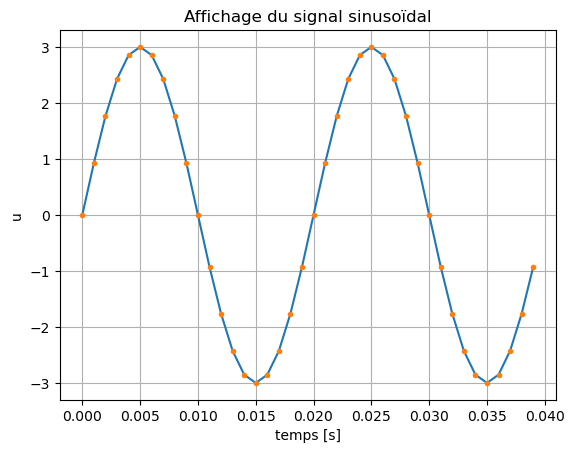

In [3]:

A = 3              # amplitude
f = 50             # fréquence [Hz]
T = 1/f            # période [s]
omega = 2*np.pi*f  # pulsation [rad/s]
Np = 2             # nombre de périodes à afficher
delta_t = 1e-3     # période d'échantillonnage

### Votre code

t_vec = np.arange(0, Np*T, delta_t)
u_vec = A*np.sin(omega*t_vec)

plt.figure()
plt.plot(t_vec, u_vec, t_vec, u_vec, '.')

plt.xlabel('temps [s]')
plt.ylabel('u')

plt.title('Affichage du signal sinusoïdal')
plt.grid()

plt.show()
###

## Exercice 2 : "Dessin d'un cercle sur matplotlib"

Dans cet exercice, vous devez utiliser la fonction plot de matplotlib pour dessiner un cercle de rayon 1, ainsi qu'un hexagone inscrit dans le cercle.

1. Déclarer un vecteur $\theta_1$, contenant 1000 points répartis linéairement entre 0 et $2\pi$
2. Définir, `x1` et `y1` en fonction de $\theta_1$ :
   * $x1 = cos(\theta_1)$
   * $y1 = sin(\theta_1)$
3. Créer une figure `matplotlib`, et représenter graphiquement `y1` en fonction de `x1`.
4. Ajouter, sur le même graphique, un hexagone inscrit dans le cercle. Vous allez pour cela utiliser les mêmes fonctions que pour le cercle :
    * Déclarer un vecteur $\theta_2$, contenant cette fois-ci 7 points, répartis linéairement entre 0 et $2\pi$
    * Définir `x2` et `y2` en fonciton de $\theta_2$
    * Représenter graphiquement `y2` en fonction de `x2`. La courbe va contenir uniquement 7 points (dont 2 aux mêmes coordonnées), situés sur le cercle unité. Matplotlib va relier les points pour former un hexagone.
5. Mettez en forme le graphique avec :
    * Un titre
    * Des labels sur les axes
    * Un quadrillage
6. Assurez-vous que les axes du graphique soient orthogonaux. Vous pouvez pour cela utiliser `plt.axis('equal')`.


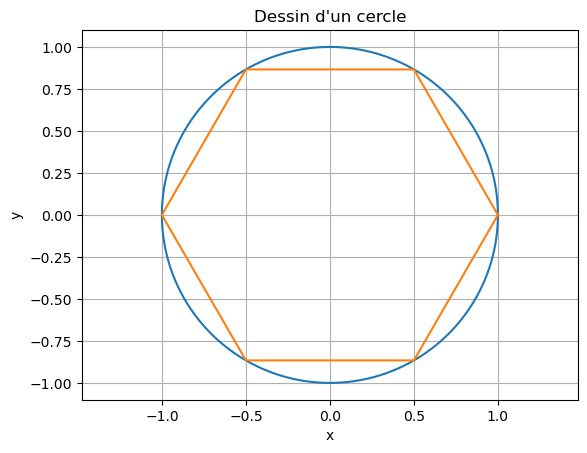

In [4]:
### Votre code

theta1 = np.linspace(0,2*np.pi,1000)
x1 = np.cos(theta1)
y1 = np.sin(theta1)

theta2 = np.linspace(0,2*np.pi,7)
x2 = np.cos(theta2)
y2 = np.sin(theta2)


plt.figure()
plt.plot(x1,y1)
plt.plot(x2,y2)

plt.xlabel('x')
plt.ylabel('y')

plt.title('Dessin d\'un cercle')
plt.grid()
plt.axis('equal')

plt.show()
###





## Exercice 3 : "Droite bruitée et régression linéaire"

Cet exercice a pour but de créer un nuage de points autour d'une droite donnée $y(x) = 3 x + 2$.
Pour cela on va rajouter du `bruit gaussien` sur les ordonnées.
Ensuite, à partir du nuage de points, on aimerait retrouver la droite d'origine avec l'aide d'une régression (problème aux moindres carrés).

1. Avec l'aide de `Polynomial` introduire le polynôme correspondant à la droite $y(x)$
2. Créer un vecteur abscisse avec 100 points répartis linéairement entre 0 et 4.
3. Evaluer le polynôme sur ce vecteur abscisse et rajouter un bruit gaussien avec l'aide de la fonction `np.random.randn`.
4. Calculer à partir du nuage de points la droite de régression en utilisant `Polynomial.fit`().
5. Superposer la droite de régression dans le graphique !


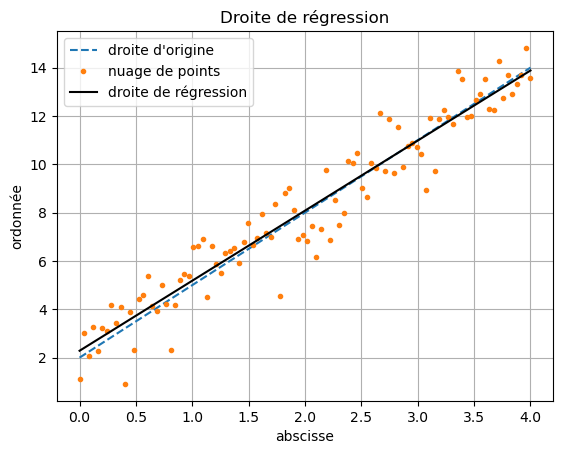

In [8]:

from numpy.polynomial import Polynomial


### votre code

coeff = np.array([2, 3])
p1 = Polynomial(coeff)
N  = 100
x  = np.linspace(0, 4, N)
y  = p1(x)
yb = y + np.random.randn(N)  # rajout de bruit gaussien

p1reg = Polynomial.fit(x, yb, 1)  # calculer le polynôme de régression de degré 1 (=droite)
yreg = p1reg(x)

plt.figure()
plt.plot(x, y, '--', label = "droite d'origine")
plt.plot(x, yb, '.', label = "nuage de points")
plt.plot(x, yreg, 'k', label = "droite de régression")
plt.grid()
plt.title('Droite de régression')
plt.xlabel('abscisse')
plt.ylabel('ordonnée')
plt.legend()
plt.show()
###



## Exercice 4 : "Echelles log et sousplots"

L'objectif est d'afficher la fonction $f(x)=\frac{1}{x}$ (hyperbole) une fois sur des échelles lin-lin, et une fois sur des échelles log-log. Le graphique devrait comporter deux sous-plots.

1. Avec l'aide de `np.linspace` créez une abscisse `x_vec1` avec 50 points linéairement répartis entre 0.1 et 10.
2. Créez l'ordonnée correspondante `y_vec1` pour l'hyperbole.
3. Avec l'aide de `np.logspace` créez une abscisse `x_vec2` avec 50 points logarithmiquement répartis entre 0.1 et 10.
2. Créez l'ordonnée correspondante `y_vec2`.
3. Avec l'aide de `plt.subplot()`, afficher sur une même figure l'allure de l'hyperbole en échelles linéaires et en échelles logarithmiques.

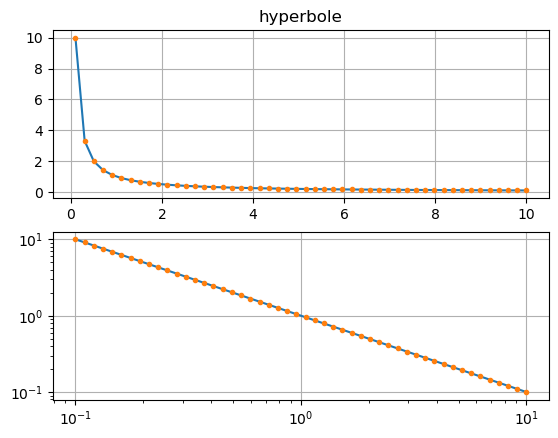

In [9]:
### Votre code
xvec1 = np.linspace(0.1, 10, 50)
yvec1 = 1/xvec1

xvec2 = np.logspace(-1, 1, 50)
yvec2 = 1/xvec2

# Création de la figure
plt.figure()

# 1er subplot. Séparation de la figure en 3 lignes et une colone, sélection du premier subplot
plt.subplot(2,1,1)
plt.plot(xvec1, yvec1, xvec1, yvec1, '.')
plt.grid()
plt.title('hyperbole')

# 2ème subplot. Même découpage que subplot n°1, sélection du deuxième subplot
plt.subplot(2,1,2)
plt.loglog(xvec2, yvec2, xvec2, yvec2, '.')
plt.grid()

plt.show()

###